# NB7 · Final figures, tables and the released catalogue

The last step of the roadmap. NB7 computes no new method result; everything is read from `results/`.

**1. The final catalogue** (D72) → `results/catalogue_final/`, released with a README (contribution 4):
- south dead and fill items: fusion with the main detector (NB4 §8b);
- Marrakech: NB3 fusion;
- clock and transfer items: the label model;
- detector-only candidates: `XS###` in the south, `XM###` in Marrakech.

**2. Figures the original plan asked for that were not drawn yet:**
- **Fig 1:** a real basemap (Natural Earth 1:50m land, no boundaries drawn; D73), and the coverage panel with rule engine v1's qualifying runs (D16);
- **Fig 2:** the typology, with the straight-line-fill signature;
- **Fig 6:** the framework.

**3. Figures regenerated with the fixes noted during the project** (D74):
- Fig 8: x-axis day labels; level scores recomputed and checked against F29;
- Fig 9: the learned-graph ablation row added;
- E4: built from v1, with final labels;
- E6: final labels;
- E19: legend fixed; panel (c) shows the final candidates;
- E22: legend fixed;
- Fig 12: panel (c) from all 30 NB4 test datasets (`tools/outage_all_datasets.py`, D76; run it before this notebook), not NB5's 4.

**4. The paper set** (D75) → `results/paper/`:
- the main and supplementary figures under their paper numbers, with draft captions in `MANIFEST.md`;
- every table as CSV: Tables 1–9 (new: 1 inventory, 2 typology, 3 rules, 4 key events) and Tables S1–S7.

Runtime about 2 min (local CPU; the LightGBM pickle in `results/benchmark_v1/models/` is needed for Fig 8).

In [1]:
import sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import matplotlib.pyplot as plt
import rules_v1 as R1, detector as D, transfer as T
import paper_figures as PF, paper_regen as RG, paper_tables as PT
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)
FIG = ROOT / "results" / "figures"
LAND = ROOT / "data" / "external" / "natural_earth" / "ne_50m_land.geojson"
T0 = time.time()
res = R1.build(ROOT / "data" / "raw" / "Data Morocco.xlsx")
print("rule engine v1:", len(res["items"]), "items")

rule engine v1: 327 items


## 1. The final catalogue and its release (D72)

In [2]:
cat = PF.final_catalogue(); eps = PF.final_episodes(cat); ke = PF.key_events_table(cat, eps)
out = PT.release_catalogue(cat, eps, ke)
print(len(cat), "entries:", cat.groupby(["system", "source"]).size().to_dict())
display(cat.groupby(["system", "label"]).size().unstack(fill_value=0))
display(cat.label_source.value_counts())
display(ke)
print("released to", out)

404 entries: {('Marrakech', 'detector'): 7, ('Marrakech', 'rule'): 64, ('south', 'detector'): 70, ('south', 'rule'): 263}


label,A1,A2,A3,A4,G2,G3,G4,G5,N
system,,,,,,,,,
Marrakech,0,0,7,2,0,35,13,0,14
south,4,58,98,12,1,17,60,1,82


label_source
fusion, main detector (NB4 8b)    296
fusion, NB3                        62
label model (NB2)                  46
Name: count, dtype: int64

,guide_id,item,kind,start,duration_h,zones,label,confidence,episode,episode_sequence
0,C01,D052,dead,2022-10-23 08:10:00,1.50,L5,G4,0.9625,EP020,G4(0.96) → A3(1.00) → A3(1.00) → G3(0.70)
1,C01,D053,dead,2022-10-23 18:30:00,15.00,L5,G3,0.6976,EP020,G4(0.96) → A3(1.00) → A3(1.00) → G3(0.70)
2,C01,F025,fill,2022-10-23 09:40:00,1.50,L5,A3,0.9993,EP020,G4(0.96) → A3(1.00) → A3(1.00) → G3(0.70)
3,C01,F026,fill,2022-10-23 11:20:00,7.17,L5,A3,0.9991,EP020,G4(0.96) → A3(1.00) → A3(1.00) → G3(0.70)
4,C02,D058,dead,2022-10-29 20:40:00,108.17,F4,G3,0.9670,EP028,G3(0.97) → A3(1.00)
5,C02,F033,fill,2022-11-03 08:50:00,1.67,F4,A3,0.9996,EP028,G3(0.97) → A3(1.00)
6,C04,D064,dead,2022-11-16 22:40:00,10.17,F1,G3,0.8330,EP033,G3(0.83) → A3(1.00)
7,C04,F037,fill,2022-11-17 08:50:00,2.00,F1,A3,0.9996,EP033,G3(0.83) → A3(1.00)
8,C05/C06,D077,dead,2023-01-28 21:10:00,13.67,15 zones (Boujdour+Foum eloued+Laayoune),A1,0.9902,EP056,A2(1.00) → A2(1.00) → A1(0.99)
9,C05/C06,F051,fill,2023-01-26 01:20:00,36.00,"L1,L2,L3,L4,L5",A2,0.9964,EP056,A2(1.00) → A2(1.00) → A1(0.99)


released to C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\catalogue_final


## 2. Fig 1 — data: basemap and coverage (D73)

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/fig1_map_coverage.png


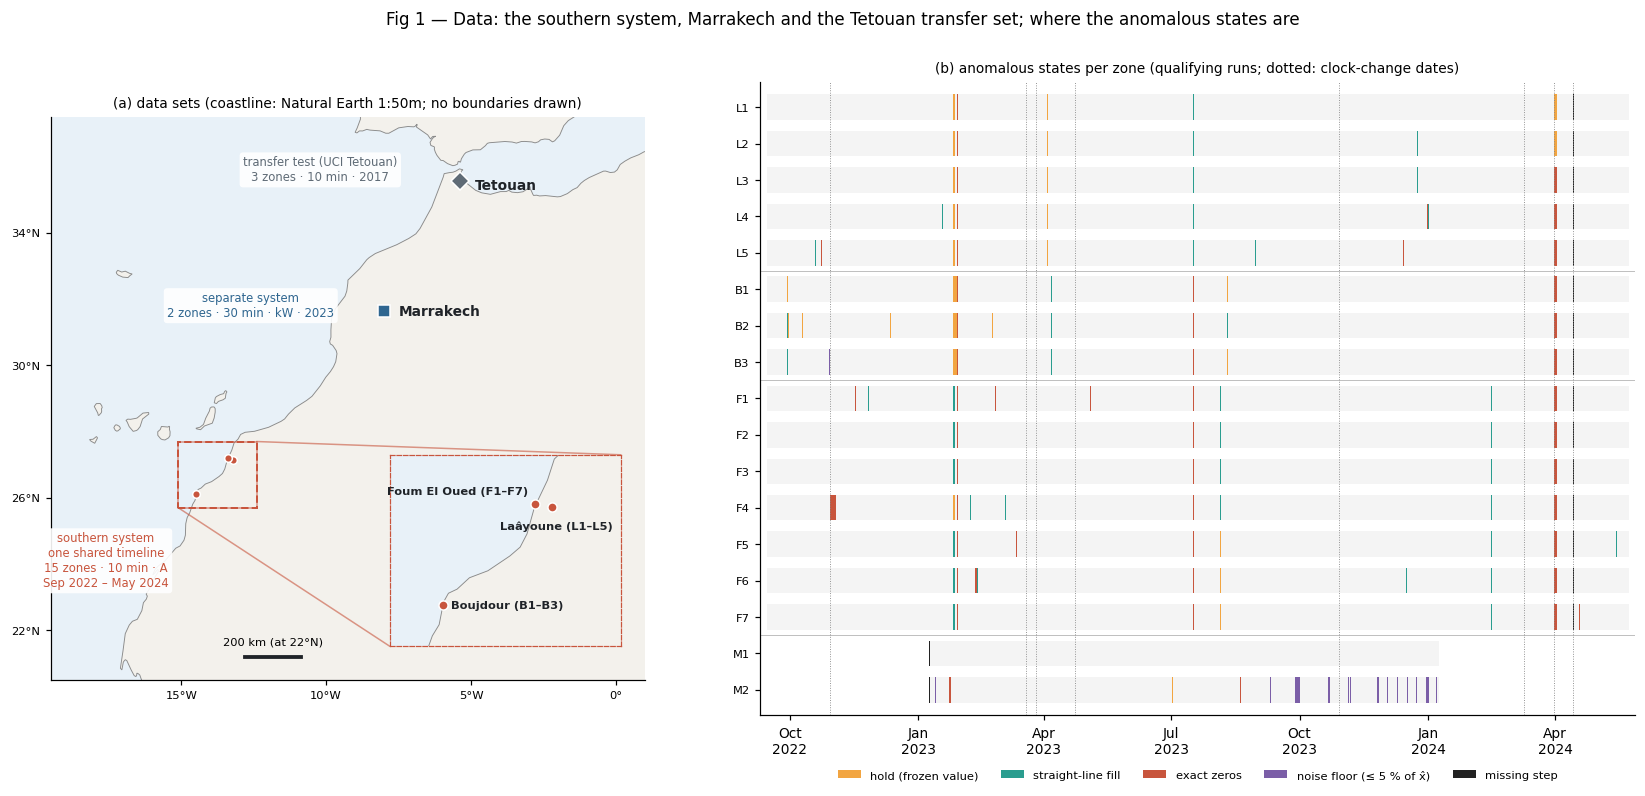

In [3]:
PF.fig1_map_coverage(res, FIG, LAND); plt.show()

## 3. Fig 2 — typology, and Table 2

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/fig2_typology.png


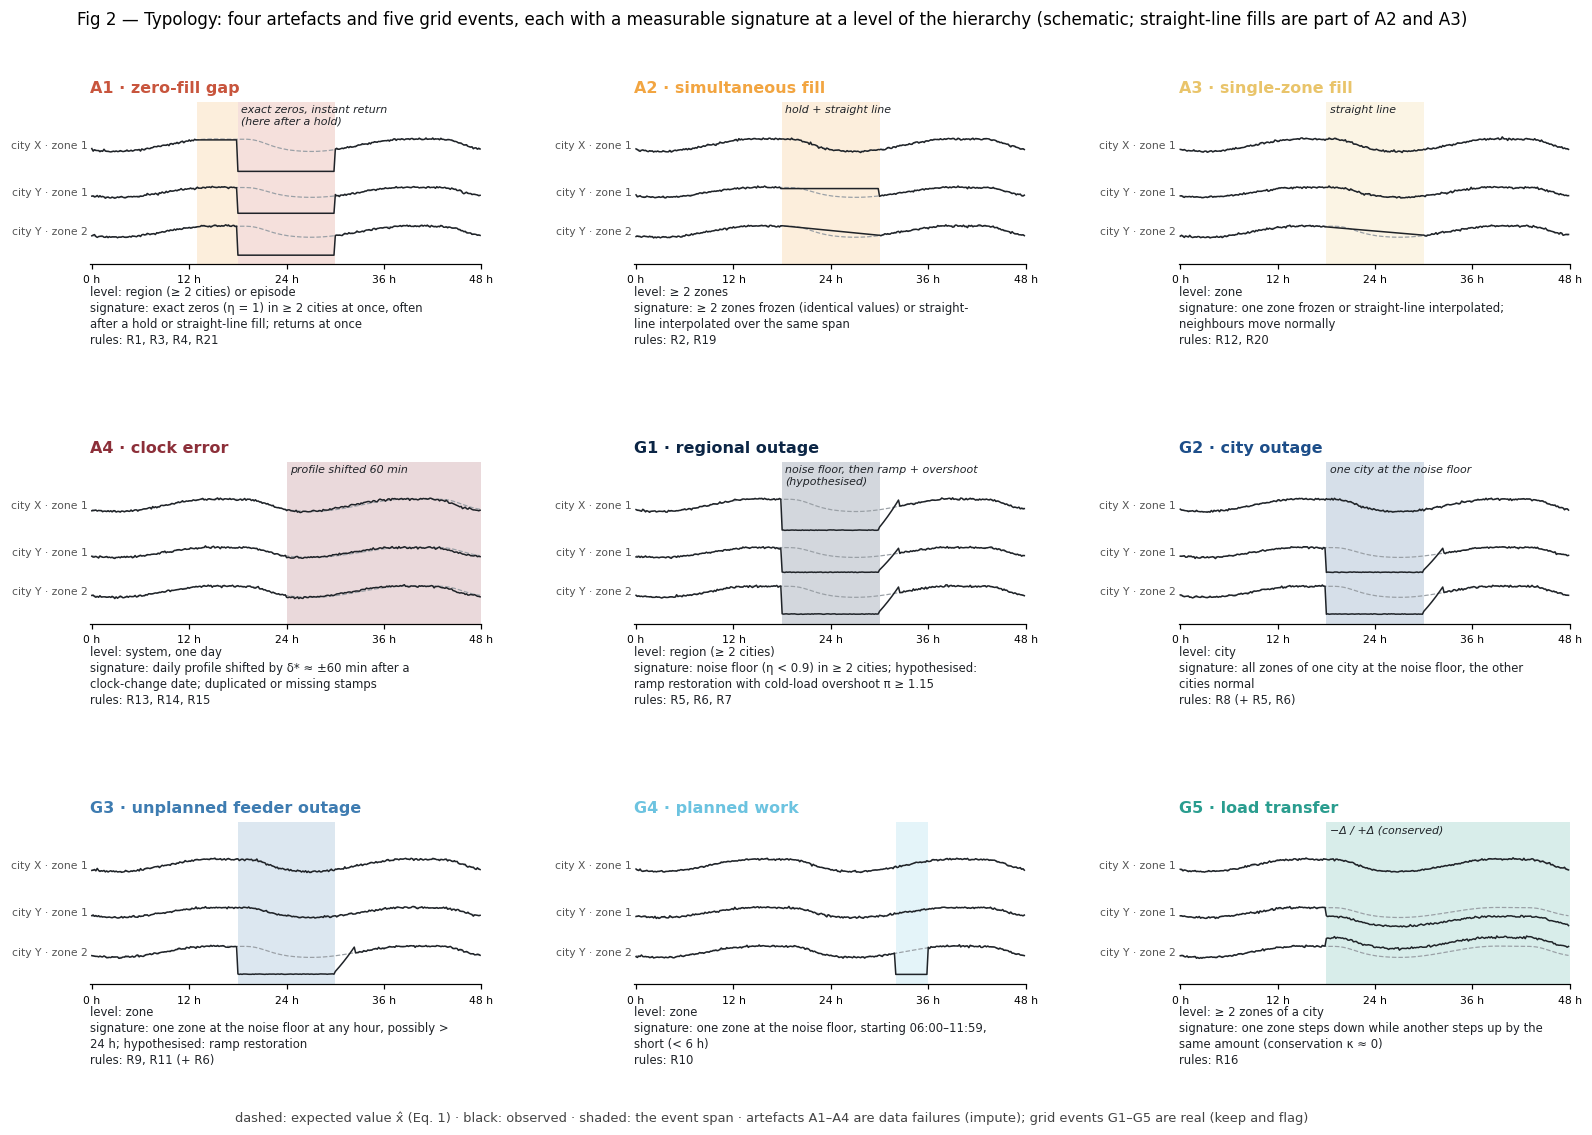

,type,name,family,hierarchy_level,measurable_signature,rules,real_rule_items,real_detector_only,injected_in_NB4
0,A1,zero-fill gap,artefact,region (≥ 2 cities) or episode,"exact zeros (η = 1) in ≥ 2 cities at once, often after a...","R1, R3, R4, R21",3,1,yes
1,A2,simultaneous fill,artefact,≥ 2 zones,≥ 2 zones frozen (identical values) or straight-line int...,"R2, R19",57,1,yes
2,A3,single-zone fill,artefact,zone,one zone frozen or straight-line interpolated; neighbour...,"R12, R20",98,7,yes
3,A4,clock error,artefact,"system, one day",daily profile shifted by δ* ≈ ±60 min after a clock-chan...,"R13, R14, R15",14,0,no (calendar-gated rules)
4,G1,regional outage,grid event,region (≥ 2 cities),noise floor (η < 0.9) in ≥ 2 cities; hypothesised: ramp ...,"R5, R6, R7",0,0,yes (no real example)
5,G2,city outage,grid event,city,"all zones of one city at the noise floor, the other citi...","R8 (+ R5, R6)",1,0,yes
6,G3,unplanned feeder outage,grid event,zone,"one zone at the noise floor at any hour, possibly > 24 h...","R9, R11 (+ R6)",52,0,yes
7,G4,planned work,grid event,zone,"one zone at the noise floor, starting 06:00–11:59, short...",R10,70,3,yes
8,G5,load transfer,grid event,≥ 2 zones of a city,one zone steps down while another steps up by the same a...,R16,1,0,no (weeks long)


In [4]:
PF.fig2_typology(FIG); plt.show()
typology = PF.table2_typology(cat); display(typology)

## 4. Fig 6 — framework

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/fig6_framework.png


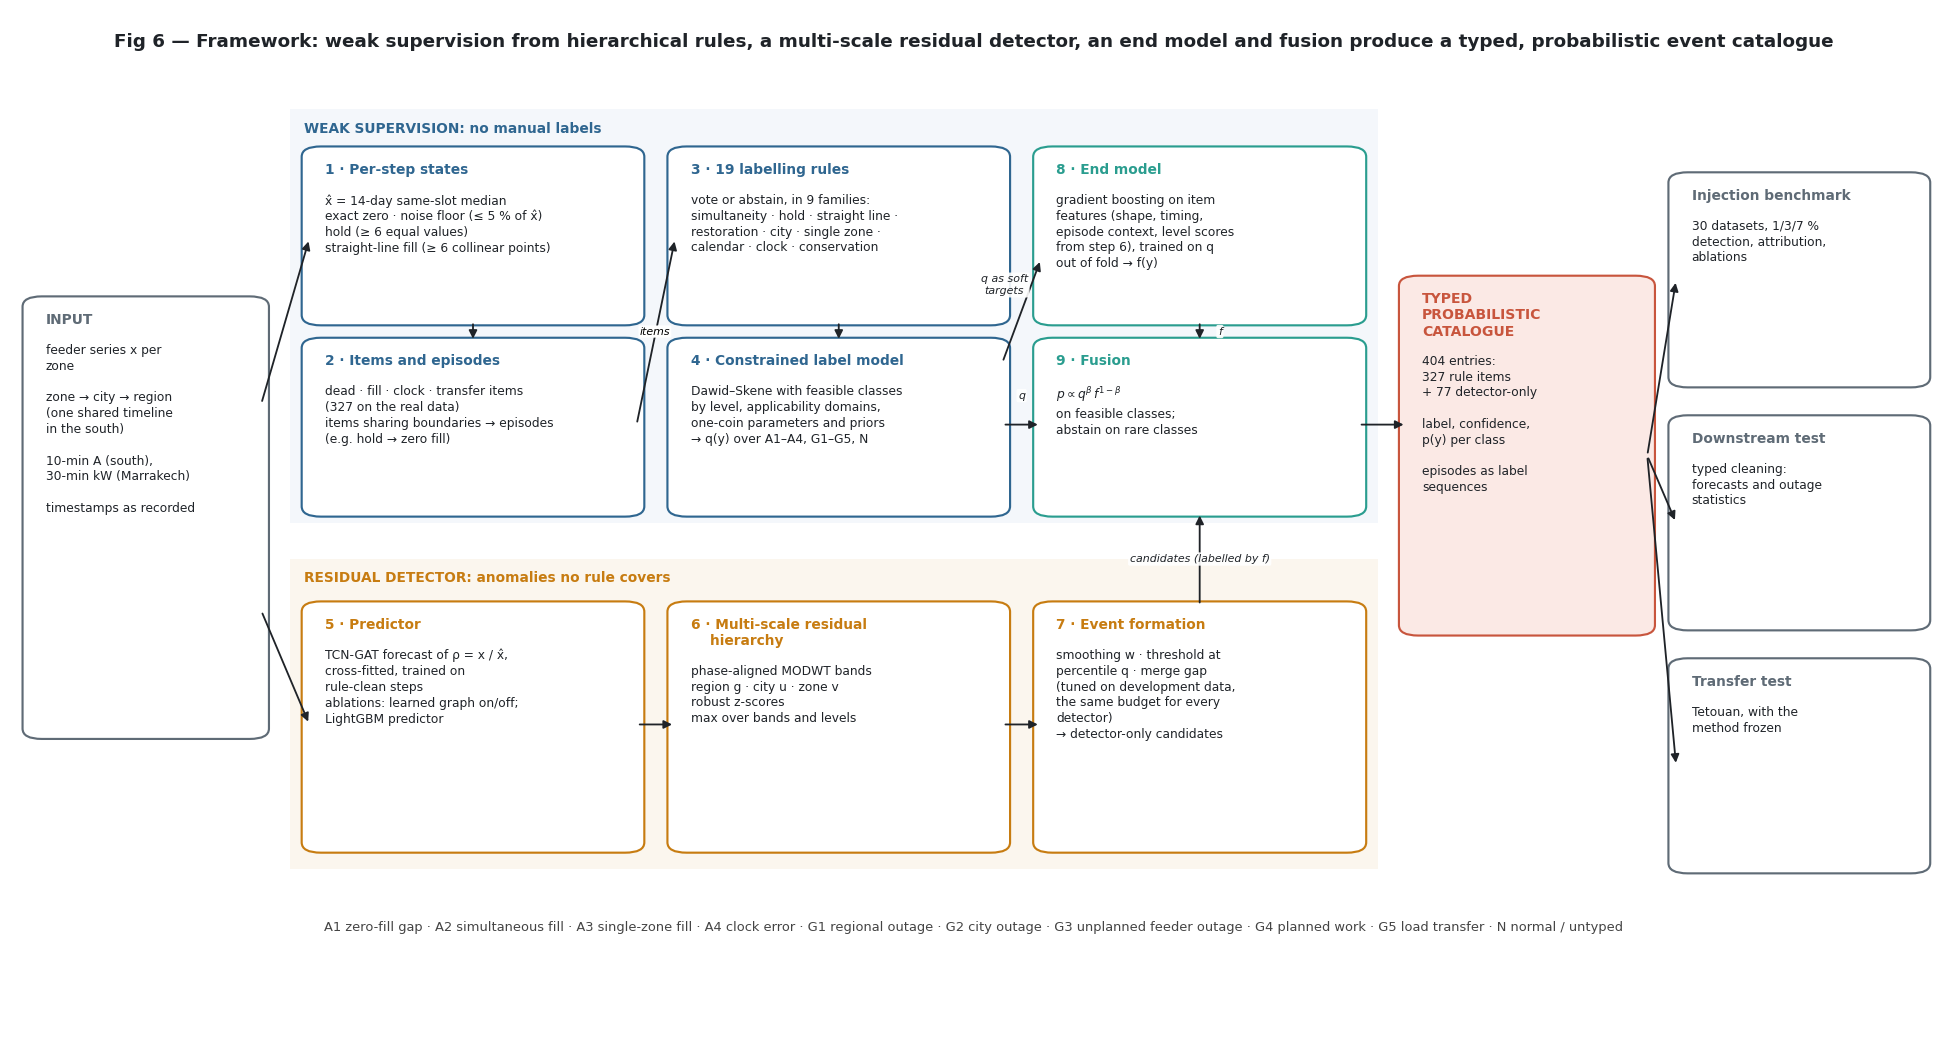

In [5]:
PF.fig6_framework(FIG, n_items=int((cat.source == "rule").sum()), n_det=int((cat.source == "detector").sum())); plt.show()

## 5. Regenerated figures (D74)

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/fig8_residual_hierarchy.png


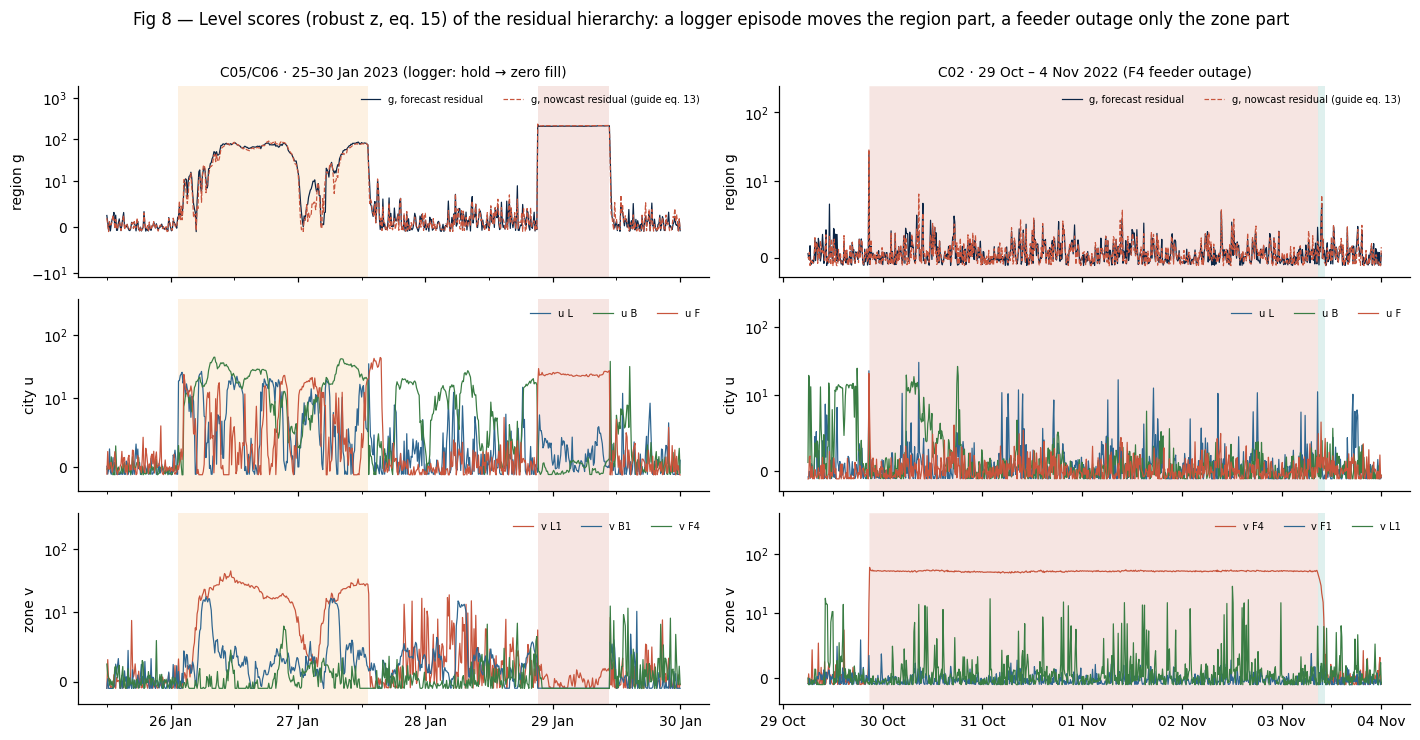

{'C05/C06 · 25–30 Jan 2023 (logger: hold → zero fill)': {'g_forecast_max': 218.0, 'g_nowcast_max': 232.6}, 'C02 · 29 Oct – 4 Nov 2022 (F4 feeder outage)': {'g_forecast_max': 27.4, 'g_nowcast_max': 29.0}}


saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/fig9_detection.png


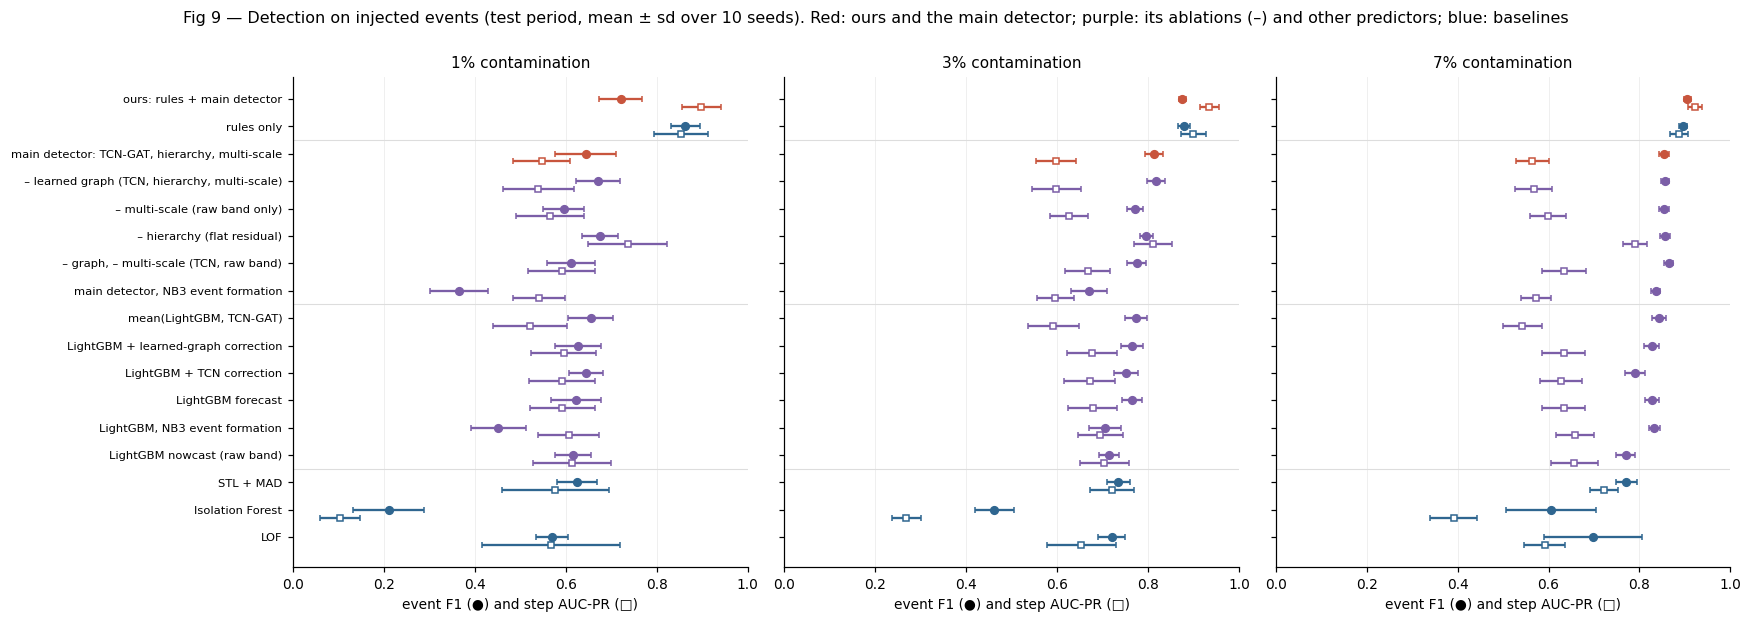

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E4_signatures.png


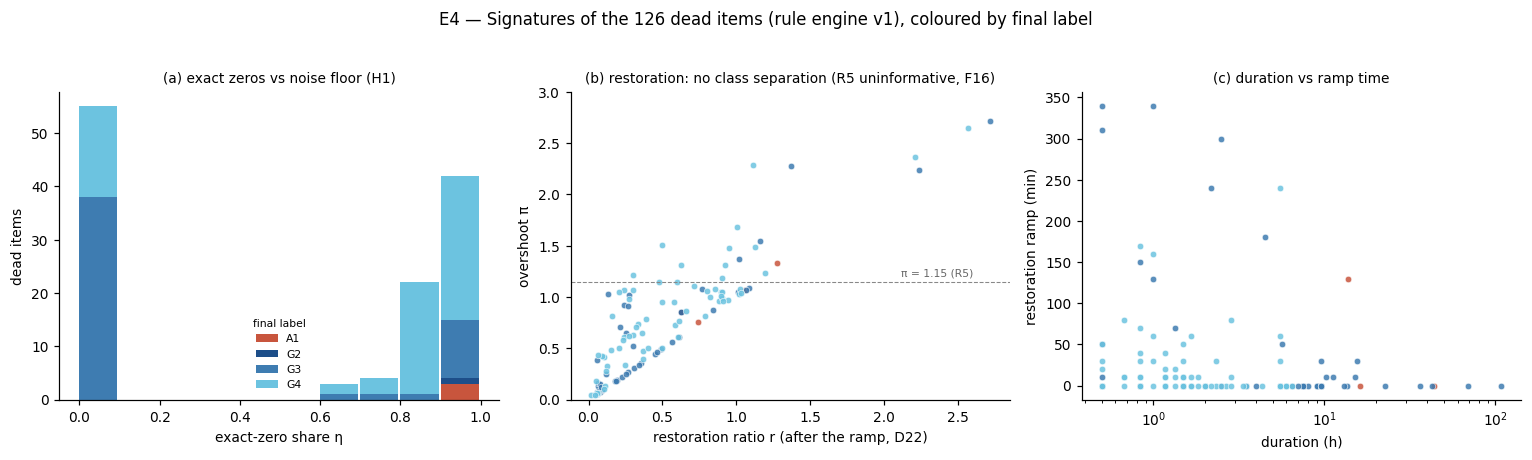

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E6_catalogue_timeline.png


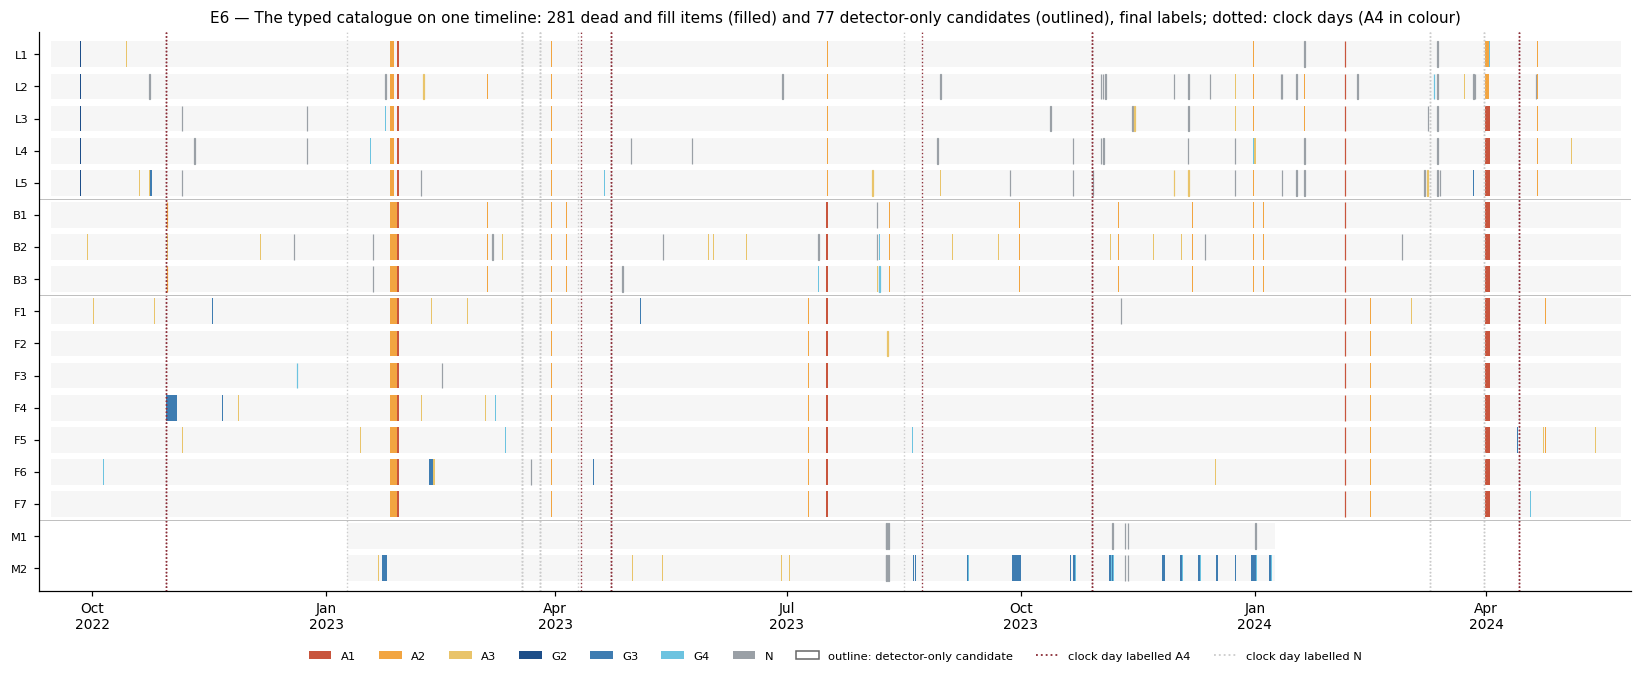

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E19_end_model.png


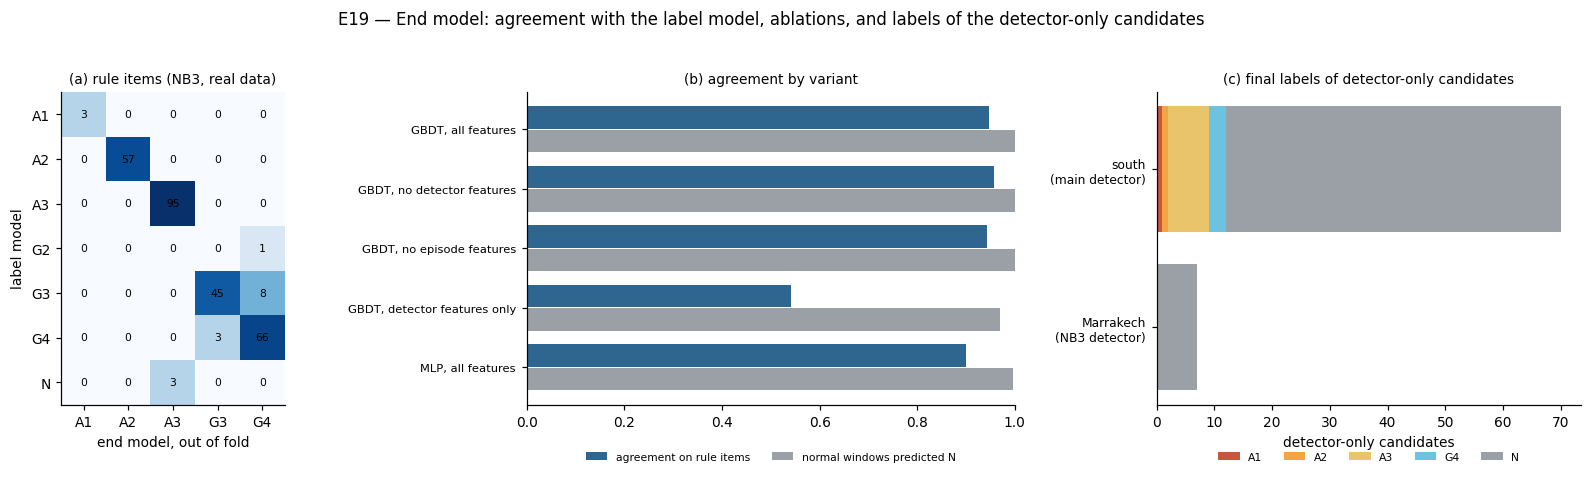

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E22_tetouan_series.png


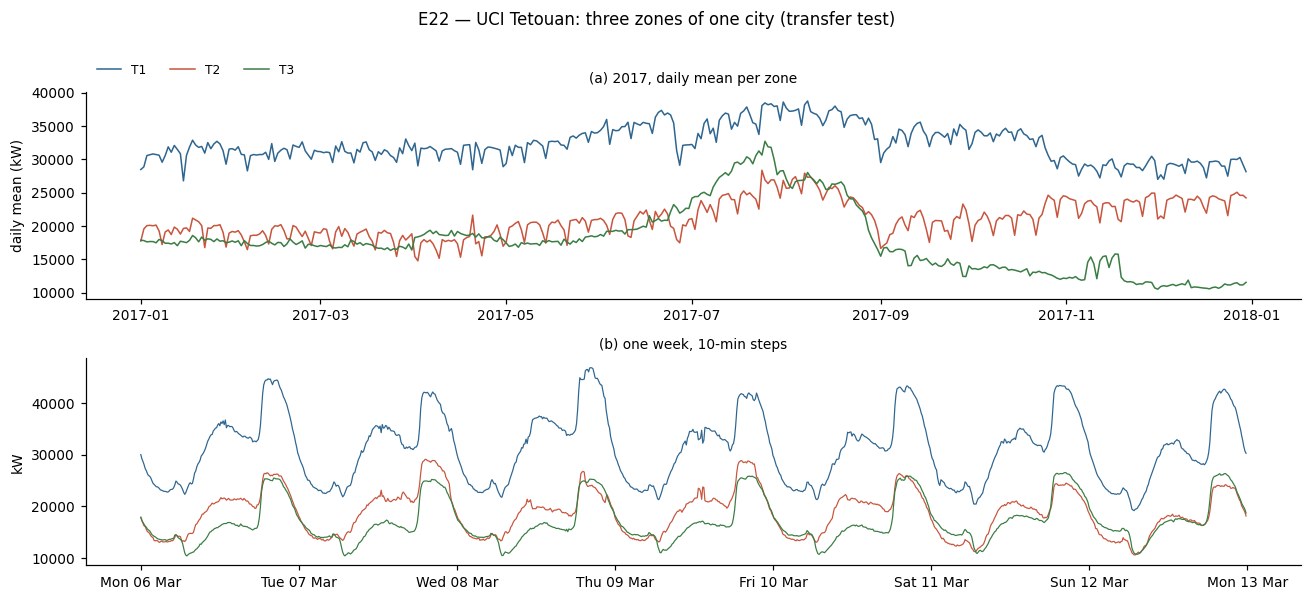

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/fig12_downstream.png


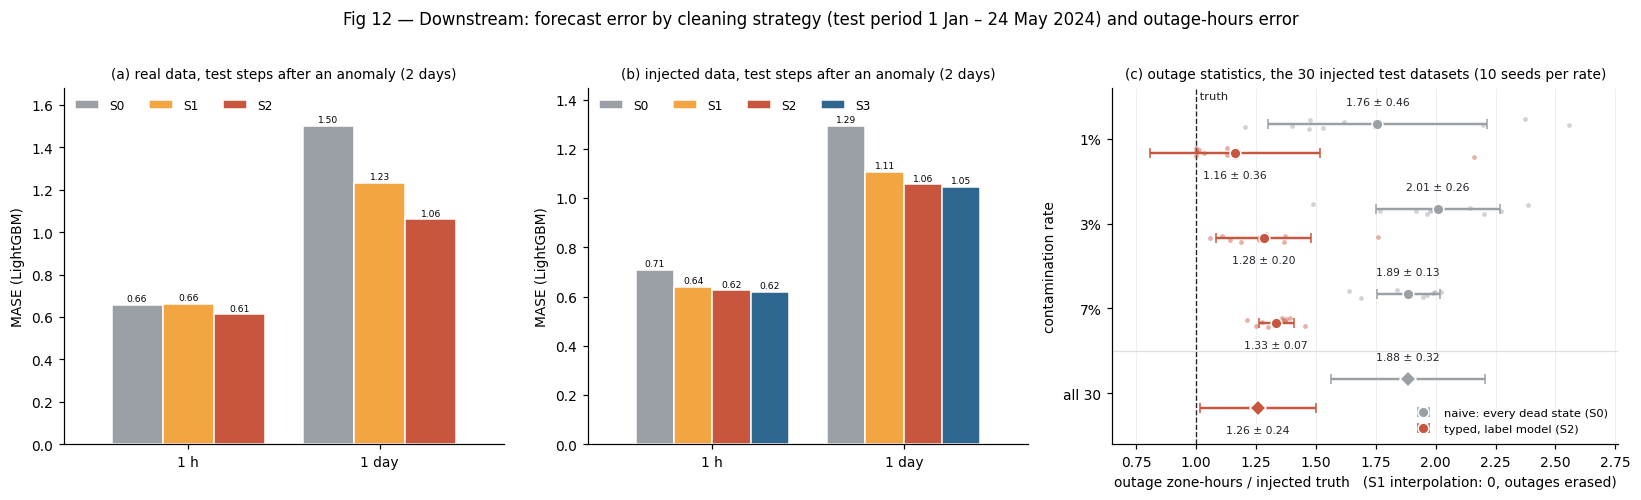

cross-fitting split still 2023-07-01


In [6]:
check = RG.fig8_hierarchy(res, FIG); plt.show()
print(check)
c = check["C05/C06 · 25–30 Jan 2023 (logger: hold → zero fill)"]
assert (c["g_forecast_max"], c["g_nowcast_max"]) == (218.0, 232.6), "Fig 8 no longer reproduces F29"
RG.fig9_detection(FIG); plt.show()
RG.e4_signatures(cat, FIG); plt.show()
RG.e6_catalogue_timeline(cat, res, FIG); plt.show()
RG.e19_end_model(cat, FIG); plt.show()
RG.e22_tetouan(FIG); plt.show()
RG.fig12_downstream(FIG); plt.show()   # panel (c) from the 30 NB4 test datasets (D76)
print("cross-fitting split still", D.SPLIT.date())

## 6. The paper set: tables, numbered figures, manifest (D75)

In [7]:
split = D.SPLIT; T.register(); D.SPLIT = split                       # Tetouan in the city dictionaries for Table 1
_, tet, _ = T.load(ROOT / "data" / "raw" / "tetouan" / "Tetuan City power consumption.csv")
tables = PT.build_tables(res, tet, cat, eps, ke, typology)
figs = PT.build_figures()
counts = f"{len(cat)} entries: {int((cat.source == 'rule').sum())} rule items, {int((cat.source == 'detector').sum())} detector-only candidates"
PT.write_manifest(figs, tables, counts)
print(len(tables), "tables;", len(figs), "figures;", counts)
display(pd.read_csv(PT.PAPER / "tables" / "Table1_data_inventory.csv"))
display(pd.read_csv(PT.PAPER / "tables" / "Table3_rules.csv"))

28 tables; 42 figures; 404 entries: 327 rule items, 77 detector-only candidates


,city,system,zones,step_min,unit,start,end,regular_steps,missing_steps,exact_zero_zone_steps
0,Laayoune,south (one logger),5,10,A,2022-09-14 17:10:00,2024-05-24 00:00:00,88890,12,1465
1,Boujdour,south (one logger),3,10,A,2022-09-14 17:10:00,2024-05-24 00:00:00,88890,12,1413
2,Foum eloued,south (one logger),7,10,A,2022-09-14 17:10:00,2024-05-24 00:00:00,88890,12,4323
3,Marrakech,Marrakech,2,30,kW,2023-01-09 00:00:00,2024-01-08 23:30:00,17520,25,101
4,Tetouan,Tetouan (transfer),3,10,kW,2017-01-01 00:00:00,2017-12-30 23:50:00,52416,0,0


,rule,family,item_kind,n_votes,coverage,overlap,conflict,outputs,learned_precision,log_odds_a_over_b,defining
0,R1,simultaneity,dead,1,0.008,1,0,A1,1.000,3.99,False
1,R2,hold,fill,12,0.077,3,0,A2,0.991,3.50,True
2,R3,hold,dead,3,0.024,2,1,A1,0.666,3.69,False
3,R4,hold,dead,3,0.024,3,2,A1,0.333,2.89,False
4,R5,restoration,dead,21,0.167,21,2,G,0.955,0.12,False
5,R6,restoration,dead,84,0.667,84,5,G,1.000,2.17,False
6,R7,simultaneity,dead,0,0.000,0,0,NaN,NaN,NaN,NaN
7,R8,city,dead,1,0.008,0,0,G2,0.994,4.80,True
8,R9,single_zone,dead,122,0.968,116,71,G3,1.000,2.61,False
9,R10,calendar,dead,69,0.548,69,69,G4,0.964,2.76,True


## 7. Summary

In [8]:
summary = dict(
    catalogue=dict(entries=len(cat), by_system_source={f"{a} | {b}": int(v) for (a, b), v in cat.groupby(["system", "source"]).size().items()},
                   labels=cat.label.value_counts().to_dict(), labels_rule_items=cat[cat.source == "rule"].label.value_counts().to_dict()),
    fig8_check=check, figures_main=len(PT.MAIN_FIGURES), figures_supp=len(PT.SUPP_FIGURES), tables=list(tables),
    runtime_min=round((time.time() - T0) / 60, 1))
summary = json.loads(json.dumps(summary, default=int))
(PT.PAPER / "summary.json").write_text(json.dumps(summary, indent=2)); print(json.dumps(summary, indent=1)[:1500])

{
 "catalogue": {
  "entries": 404,
  "by_system_source": {
   "Marrakech | detector": 7,
   "Marrakech | rule": 64,
   "south | detector": 70,
   "south | rule": 263
  },
  "labels": {
   "A3": 105,
   "N": 96,
   "G4": 73,
   "A2": 58,
   "G3": 52,
   "A4": 14,
   "A1": 4,
   "G2": 1,
   "G5": 1
  },
  "labels_rule_items": {
   "A3": 98,
   "G4": 70,
   "A2": 57,
   "G3": 52,
   "N": 31,
   "A4": 14,
   "A1": 3,
   "G2": 1,
   "G5": 1
  }
 },
 "fig8_check": {
  "C05/C06 \u00b7 25\u201330 Jan 2023 (logger: hold \u2192 zero fill)": {
   "g_forecast_max": 218.0,
   "g_nowcast_max": 232.6
  },
  "C02 \u00b7 29 Oct \u2013 4 Nov 2022 (F4 feeder outage)": {
   "g_forecast_max": 27.4,
   "g_nowcast_max": 29.0
  }
 },
 "figures_main": 14,
 "figures_supp": 28,
 "tables": [
  "Table1_data_inventory",
  "Table2_typology",
  "Table3_rules",
  "Table4_key_events",
  "Table5_detection",
  "Table5_wilcoxon",
  "Table6_attribution",
  "Table7a_pipeline",
  "Table7b_detector_ablations_3pct",
  "Table7